# Inflação, juros e câmbio no Brasil

Esta análise combina séries do Sistema Gerenciador de Séries Temporais (SGS) do Banco Central: IPCA mensal (código 433, %), Selic anual (código 12, % a.a.) e câmbio do dólar (código 1, BRL por USD). Os dados são lidos do PostgreSQL por views SQL.

Vamos observar a inflação acumulada em 12 meses, estimar o juro real pela equação de Fisher e explorar a associação entre variação mensal do câmbio e IPCA. Correlação não demonstra causalidade.

In [7]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import text

ROOT = Path.cwd()
if not (ROOT / "sql" / "02_views.sql").exists():
    ROOT = next(path for path in ROOT.parents if (path / "sql" / "02_views.sql").exists())
sys.path.insert(0, str(ROOT))

from src.config import criar_engine

engine = criar_engine()
try:
    sql_views = (ROOT / "sql" / "02_views.sql").read_text(encoding="utf-8")
    with engine.begin() as conexao:
        conexao.exec_driver_sql(sql_views)

    ipca_12m = pd.read_sql_query(
        text("SELECT data, inflacao_12_meses_pct FROM vw_ipca_12_meses ORDER BY data"), engine
    )
    juros_reais = pd.read_sql_query(
        text("SELECT data, selic_anual_pct, inflacao_12_meses_pct, juro_real_pct FROM vw_juro_real ORDER BY data"), engine
    )
    mensal = pd.read_sql_query(
        text("SELECT data, cambio_medio_brl_por_usd, variacao_cambio_mensal_pct, ipca_mensal_pct, juro_real_pct FROM vw_analise_mensal ORDER BY data"), engine
    )
finally:
    engine.dispose()

for tabela in (ipca_12m, juros_reais, mensal):
    tabela["data"] = pd.to_datetime(tabela["data"])

print(f"IPCA 12 meses: {len(ipca_12m):,} meses; juro real: {len(juros_reais):,} meses; an?lise mensal: {len(mensal):,} meses.")
display(ipca_12m.tail())
display(juros_reais.tail())

IPCA 12 meses: 0 meses; juro real: 0 meses; an?lise mensal: 0 meses.


,data,inflacao_12_meses_pct


,data,selic_anual_pct,inflacao_12_meses_pct,juro_real_pct


## Validação das métricas

A inflação acumulada é o produto das variações mensais (1 + IPCA/100), menos 1. Com dados carregados, comparamos dezembro de 2023 com os **4,62%** do IPCA oficial divulgado pelo IBGE. O juro real usa taxas anuais na mesma unidade percentual: (1 + Selic/100) / (1 + inflação 12m/100) - 1. A inflação de dezembro de 2023 é o acumulado dos 12 meses anteriores; o exemplo numérico de Fisher abaixo é apenas uma verificação aritmética.

In [8]:
# Conferência numérica independente da fórmula de Fisher: 10% nominal e 4% de inflação.
selic_exemplo_pct = 10.0
inflacao_exemplo_pct = 4.0
juro_real_exemplo_pct = ((1 + selic_exemplo_pct / 100) / (1 + inflacao_exemplo_pct / 100) - 1) * 100
assert np.isclose(juro_real_exemplo_pct, 5.76923076923077)
print(f"Fisher (10% nominal, 4% inflação): {juro_real_exemplo_pct:.4f}% real.")

referencia_ipca = pd.Timestamp("2023-12-01")
resultado_2023 = ipca_12m.loc[ipca_12m["data"].eq(referencia_ipca), "inflacao_12_meses_pct"]
if not resultado_2023.empty:
    ipca_calculado = float(resultado_2023.iloc[0])
    ipca_oficial = 4.62
    diferenca_pp = ipca_calculado - ipca_oficial
    print(f"IPCA 12m em dez/2023: {ipca_calculado:.2f}% (IBGE: {ipca_oficial:.2f}%; diferença: {diferenca_pp:+.2f} p.p.).")
    assert abs(diferenca_pp) <= 0.02, "O acumulado diverge do IPCA oficial de 2023."
else:
    print("Validação oficial do IPCA 2023 pendente: a view não contém dez/2023; carregue os dados SGS 433 desde 2023.")

Fisher (10% nominal, 4% inflação): 5.7692% real.
Validação oficial do IPCA 2023 pendente: a view não contém dez/2023; carregue os dados SGS 433 desde 2023.


## Associação entre câmbio e inflação

Usamos a variação percentual mensal da média do câmbio (BRL por USD) e o IPCA mensal, não os níveis das séries. Isso evita interpretar uma tendência comum como relação entre mudanças. A correlação de Pearson varia de -1 a 1 e resume associação linear no período observado; não controla por defasagens, política monetária, choques externos ou outros fatores, portanto não implica causalidade.

In [ ]:
pares = mensal[["variacao_cambio_mensal_pct", "ipca_mensal_pct"]].dropna()
if len(pares) >= 2 and pares.std(ddof=0).gt(0).all():
    correlacao = float(np.corrcoef(
        pares["variacao_cambio_mensal_pct"].to_numpy(),
        pares["ipca_mensal_pct"].to_numpy(),
    )[0, 1])
    print(f"Correlação de Pearson câmbio ? IPCA mensal: {correlacao:.3f} (n={len(pares)} meses).")
else:
    correlacao = np.nan
    print(f"Correlação não calculada: são necessários pelo menos dois pares variáveis; disponíveis {len(pares)}.")

if not mensal.empty:
    display(mensal.tail())

Correlação n?o calculada: s?o necess?rios pelo menos dois pares vari?veis; dispon?veis 0.


## Evolução das séries

Os painéis mantêm escalas e unidades explícitas. A primeira figura compara indicadores expressos em percentual ao ano; a segunda mostra câmbio em BRL por USD; a terceira relaciona as duas variações mensais em percentual.

C:\Users\gabri\AppData\Local\Temp\ipykernel_3632\3888086138.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()


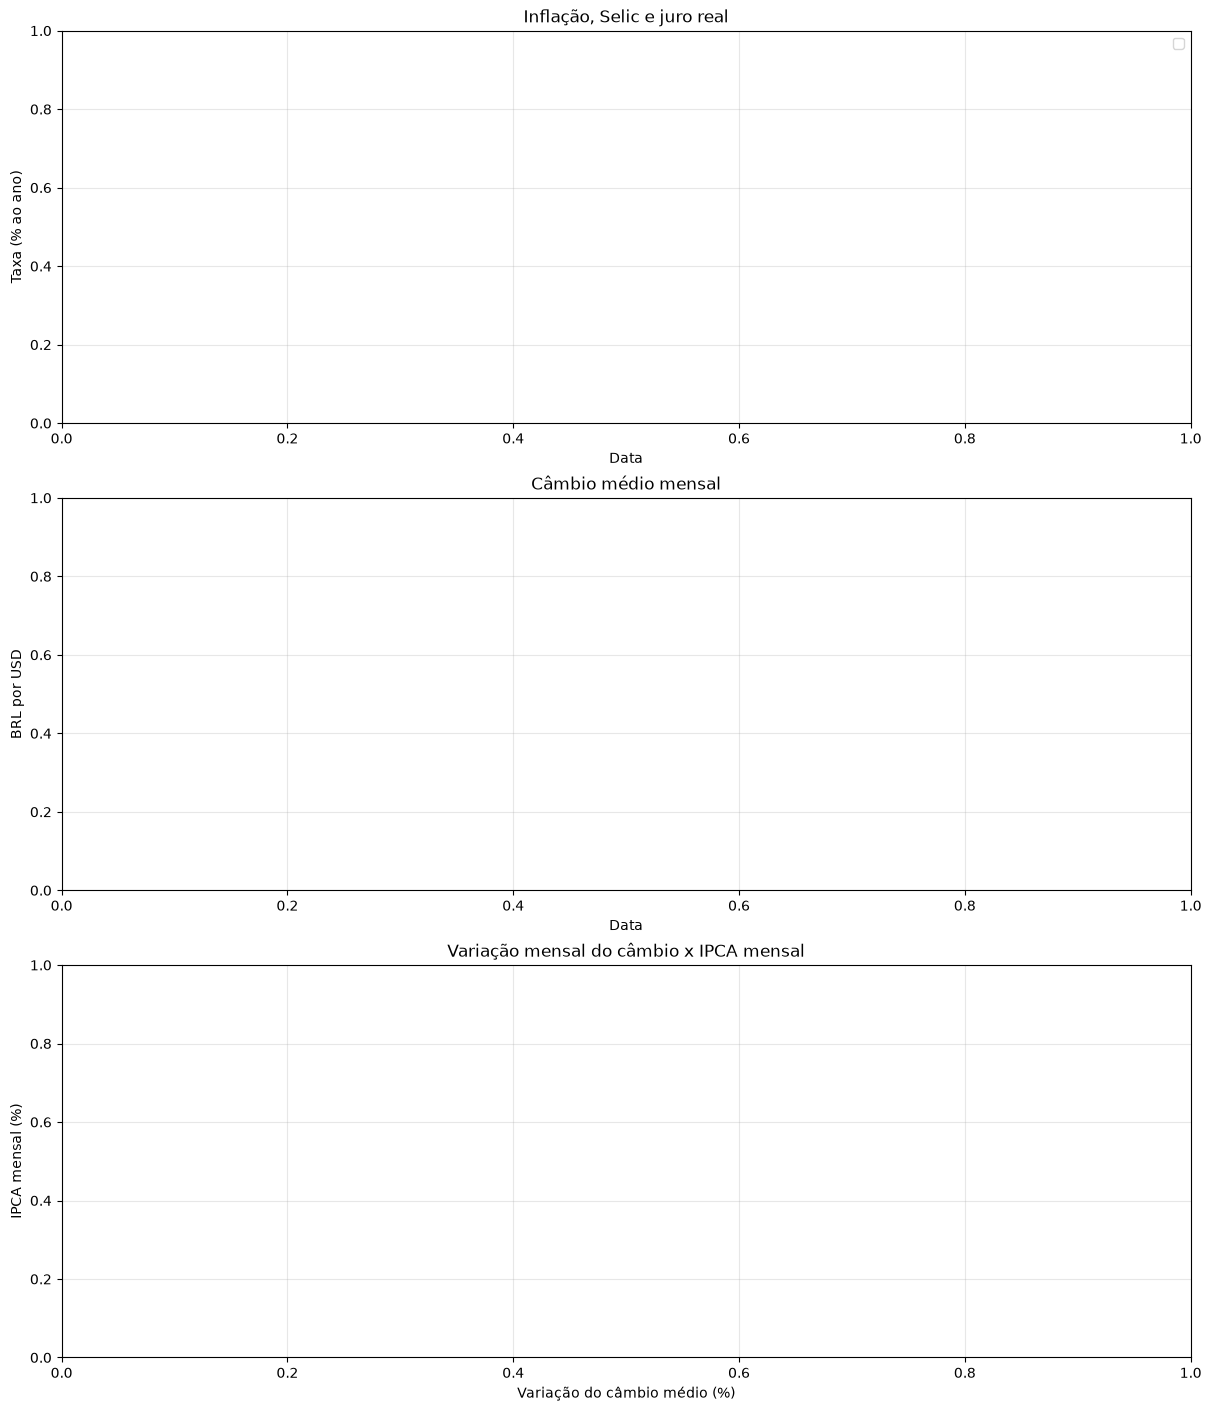

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(12, 14), constrained_layout=True)

if not ipca_12m.empty:
    axes[0].plot(ipca_12m["data"], ipca_12m["inflacao_12_meses_pct"], label="IPCA acumulado em 12 meses")
if not juros_reais.empty:
    axes[0].plot(juros_reais["data"], juros_reais["selic_anual_pct"], label="Selic anual (?ltimo valor do m?s)")
    axes[0].plot(juros_reais["data"], juros_reais["juro_real_pct"], label="Juro real ex-post (Fisher)")
axes[0].set_title("Inflação, Selic e juro real")
axes[0].set_ylabel("Taxa (% ao ano)")
axes[0].set_xlabel("Data")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

if not mensal.empty:
    axes[1].plot(mensal["data"], mensal["cambio_medio_brl_por_usd"], color="tab:green")
axes[1].set_title("Câmbio médio mensal")
axes[1].set_ylabel("BRL por USD")
axes[1].set_xlabel("Data")
axes[1].grid(True, alpha=0.3)

if not pares.empty:
    axes[2].scatter(pares["variacao_cambio_mensal_pct"], pares["ipca_mensal_pct"], alpha=0.7)
axes[2].set_title("Variação mensal do câmbio x IPCA mensal")
axes[2].set_xlabel("Variação do câmbio médio (%)")
axes[2].set_ylabel("IPCA mensal (%)")
axes[2].grid(True, alpha=0.3)
plt.show()

## Conclusões

Os achados abaixo são calculados a partir dos dados disponíveis no banco. Quando ainda não há carga histórica, o notebook registra essa limitação em vez de apresentar conclusões inventadas.

In [ ]:
achados = []
if not ipca_12m.empty:
    ultimo_ipca = ipca_12m.iloc[-1]
    achados.append(f"Em {ultimo_ipca['data']:%m/%Y}, o IPCA acumulado em 12 meses foi {ultimo_ipca['inflacao_12_meses_pct']:.2f}%.")
if not juros_reais.empty:
    ultimo_juro = juros_reais.iloc[-1]
    achados.append(f"Em {ultimo_juro['data']:%m/%Y}, a Selic anual foi {ultimo_juro['selic_anual_pct']:.2f}% e o juro real ex-post estimado foi {ultimo_juro['juro_real_pct']:.2f}%.")
if not mensal.empty:
    ultimo_cambio = mensal.dropna(subset=["cambio_medio_brl_por_usd"]).iloc[-1]
    achados.append(f"Em {ultimo_cambio['data']:%m/%Y}, o câmbio médio foi {ultimo_cambio['cambio_medio_brl_por_usd']:.2f} BRL/USD.")
if np.isfinite(correlacao):
    achados.append(f"No período com dados pareados, a correlação câmbio ? IPCA foi {correlacao:.3f} (n={len(pares)}); isso não estabelece causalidade.")
if len(achados) < 3:
    achados.append("A validação do IPCA oficial de 2023 só pode ser concluída depois de carregar a série SGS 433 com os 12 meses de 2023.")
if len(achados) < 3:
    achados.append("As séries disponiveis são insuficientes para uma interpretação empírica; execute primeiro o pipeline de carga e rode novamente o notebook.")
for numero, achado in enumerate(achados[:5], start=1):
    print(f"{numero}. {achado}")

print("Limitação: correlação contemporânea não identifica causalidade nem efeitos defasados.")

1. A validação do IPCA oficial de 2023 só pode ser concluída depois de carregar a série SGS 433 com os 12 meses de 2023.
2. As s?ries dispon?veis s?o insuficientes para uma interpreta??o emp?rica; execute primeiro o pipeline de carga e rode novamente o notebook.
Limitação: correlação contemporânea não identifica causalidade nem efeitos defasados.


### Fontes e convenções

- BCB/SGS: séries 433 (IPCA mensal), 12 (Selic anual) e 1 (câmbio). Os dados observados dependem do período carregado no PostgreSQL.
- IBGE, IPCA de dezembro de 2023: [IPCA vai a 0,56% em dezembro e fecha o ano em 4,62%](https://agenciadenoticias.ibge.gov.br/agencia-sala-de-imprensa/2013-agencia-de-noticias/releases/38984-ipca-vai-a-0-56-em-dezembro-e-fecha-o-ano-em-4-62).
- O juro real é uma aproximação ex-post com a última Selic anual observada no mês, comparada ao IPCA acumulado em 12 meses; não é a taxa real esperada pelo mercado.